### News

**Read our [Gemma 3 blog](https://unsloth.ai/blog/gemma3) for what's new in Unsloth and our [Reasoning blog](https://unsloth.ai/blog/r1-reasoning) on how to train reasoning models.**

Visit our docs for all our [model uploads](https://docs.unsloth.ai/get-started/all-our-models) and [notebooks](https://docs.unsloth.ai/get-started/unsloth-notebooks).


### Installation

In [1]:
%%capture
import importlib.util
if importlib.util.find_spec("unsloth") is None:
    # Fresh environment (e.g. Google Colab): install Unsloth (pulls torch, TRL, PEFT, bitsandbytes)
    !pip install unsloth
    !pip install --no-deps unsloth_zoo
    !pip install msgspec blake3 gguf
else:
    print("Unsloth already installed - skipping pip installs (local WSL2 environment)")

In [2]:
#@title Colab Extra Install { display-mode: "form" }
# Extra installs (vLLM etc.) are only needed on Google Colab.
# Skipped here: this notebook was executed locally in WSL2 with the stack pre-installed.
import os
print("Not running on Colab - extra installs skipped.")

Not running on Colab - extra installs skipped.


### Unsloth

`FastModel` supports loading nearly any model now! This includes Vision and Text models!

In [3]:
from unsloth import FastModel
import torch

fourbit_models = [
    # 4bit dynamic quants for superior accuracy and low memory use
    "unsloth/gemma-3-1b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-4b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-12b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-27b-it-unsloth-bnb-4bit",

    # Other popular models!
    "unsloth/Llama-3.1-8B",
    "unsloth/Llama-3.2-3B",
    "unsloth/Llama-3.3-70B",
    "unsloth/mistral-7b-instruct-v0.3",
    "unsloth/Phi-4",
] # More models at https://huggingface.co/unsloth

model, tokenizer = FastModel.from_pretrained(
    model_name = "unsloth/gemma-3-4b-it-unsloth-bnb-4bit",  # pre-quantised 4-bit variant of unsloth/gemma-3-4b-it: ~3 GB download instead of ~8.5 GB, avoids on-the-fly quantisation, fits an 8 GB laptop GPU
    max_seq_length = 2048, # Choose any for long context!
    load_in_4bit = True,  # 4 bit quantization to reduce memory
    load_in_8bit = False, # [NEW!] A bit more accurate, uses 2x memory
    full_finetuning = False, # [NEW!] We have full finetuning now!
    # token = "hf_...", # use one if using gated models
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


/root/tp04-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1111 14:24:28.370000 419 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1111 14:24:28.416000 419 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!


==((====))==  Unsloth 2026.11.3: Fast Gemma3 patching. Transformers: 5.17.0.
   \\   /|    NVIDIA GeForce RTX 4060 Laptop GPU. Num GPUs = 1. Max memory: 7.996 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 8.9. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth


... (78 outputs left out)


Loading weights:  97%|█████████▋| 860/883 [00:13<00:00, 83.31it/s]


Loading weights: 100%|██████████| 883/883 [00:13<00:00, 65.19it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

Unsloth: compiling each transformer block as one region (Gemma3DecoderLayer).


We now add LoRA adapters so we only need to update a small amount of parameters!

In [4]:
model = FastModel.get_peft_model(
    model,
    finetune_vision_layers     = False, # Turn off for just text!
    finetune_language_layers   = True,  # Should leave on!
    finetune_attention_modules = True,  # Attention good for GRPO
    finetune_mlp_modules       = True,  # SHould leave on always!

    r = 8,           # Larger = higher accuracy, but might overfit
    lora_alpha = 8,  # Recommended alpha == r at least
    lora_dropout = 0,
    bias = "none",
    random_state = 3407,
)

<a name="Data"></a>
### Data Prep
We now use the `Gemma-3` format for conversation style finetunes. We use [Maxime Labonne's FineTome-100k](https://huggingface.co/datasets/mlabonne/FineTome-100k) dataset in ShareGPT style. Gemma-3 renders multi turn conversations like below:

```
<bos><start_of_turn>user
Hello!<end_of_turn>
<start_of_turn>model
Hey there!<end_of_turn>
```

We use our `get_chat_template` function to get the correct chat template. We support `zephyr, chatml, mistral, llama, alpaca, vicuna, vicuna_old, phi3, llama3, phi4, qwen2.5, gemma3` and more.

In [5]:
from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(
    tokenizer,
    chat_template = "gemma-3",
)

In [6]:
import pandas as pd
from datasets import Dataset

# The CSV header is stored as the single quoted field "input,output", which pandas
# would read as one column, so skip it and name the two columns ourselves.
df = pd.read_csv(
    "dataasilida_cleaned.csv",
    header=None, skiprows=1, names=["input", "output"],
    keep_default_na=False, na_values=[""],
)
df["input"] = df["input"].fillna("").str.strip()
df["output"] = df["output"].fillna("").str.strip()
df = df[(df["input"] != "") & (df["output"] != "")].reset_index(drop=True)

print(f"{len(df)} usable instruction/response pairs")
dataset = Dataset.from_pandas(df, preserve_index=False)

514 usable instruction/response pairs


In [7]:
dataset["input"][0]

'តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី'

In [8]:
def formatting_prompts_func(examples):
    instructions = examples["input"]
    outputs      = examples["output"]
    texts = []
    for instruction, output in zip(instructions, outputs):
      messages = [
        {
            "role": "user", 'content': instruction.strip(" ")
          },
          {
            "role": "assistant", 'content': output
          }
      ]
      #tokenizer.apply_chat_template(messages, add_generation_prompt=False , tokenize= False)
      text = tokenizer.apply_chat_template(messages, add_generation_prompt=False , tokenize= False)
      texts.append(text)
    return {"text":texts}



In [9]:
# Hold out 10% of the data for validation so we can measure validation loss.
dataset = dataset.train_test_split(test_size=0.1, seed=3407)
dataset = dataset.map(formatting_prompts_func, batched=True)
print(dataset)


Map:   0%|          | 0/462 [00:00<?, ? examples/s]


Map: 100%|██████████| 462/462 [00:00<00:00, 8019.40 examples/s]


Map:   0%|          | 0/52 [00:00<?, ? examples/s]


Map: 100%|██████████| 52/52 [00:00<00:00, 7103.20 examples/s]

DatasetDict({
    train: Dataset({
        features: ['input', 'output', 'text'],
        num_rows: 462
    })
    test: Dataset({
        features: ['input', 'output', 'text'],
        num_rows: 52
    })
})


In [10]:
dataset['train']['text'][0]

'<bos><start_of_turn>user\nតើខ្ញុំត្រូវធ្វើដូចម្តេចដើម្បីដាក់ប្រាក់ទៅក្នុងគណនី អ៉ីអនវ៉លឡេត របស់ខ្ញុំ<end_of_turn>\n<start_of_turn>model\nសូមលោកអ្នកអញ្ជើញទៅកាន់បញ្ជរដាក់ ឬដកប្រាក់របស់យើងខ្ញុំដែលមានទីតាំងនៅក្នុងផ្សារទំនើបអ៉ីអនម៉លភ្នំពេញ និង ផ្សារទំនើបអ៉ីអនម៉លសែនសុខស៊ីធី។<end_of_turn>\n'

Let's see how row 100 looks like!

In [11]:
dataset['train']['input'][0]

'តើខ្ញុំត្រូវធ្វើដូចម្តេចដើម្បីដាក់ប្រាក់ទៅក្នុងគណនី អ៉ីអនវ៉លឡេត របស់ខ្ញុំ'

In [12]:
dataset['train']['input'][0]

'តើខ្ញុំត្រូវធ្វើដូចម្តេចដើម្បីដាក់ប្រាក់ទៅក្នុងគណនី អ៉ីអនវ៉លឡេត របស់ខ្ញុំ'

Let's see how the chat template did! Notice `Gemma-3` default adds a `<bos>`!

In [13]:
dataset['train']['output'][0]

'សូមលោកអ្នកអញ្ជើញទៅកាន់បញ្ជរដាក់ ឬដកប្រាក់របស់យើងខ្ញុំដែលមានទីតាំងនៅក្នុងផ្សារទំនើបអ៉ីអនម៉លភ្នំពេញ និង ផ្សារទំនើបអ៉ីអនម៉លសែនសុខស៊ីធី។'

<a name="Train"></a>
### Train the model

Now let's use Huggingface TRL's `SFTTrainer`! More docs here: [TRL SFT docs](https://huggingface.co/docs/trl/sft_trainer).

**Key hyperparameters to understand and modify (objective 2):**
- `per_device_train_batch_size` × `gradient_accumulation_steps` = effective batch size (2 × 4 = 8 here). Larger batches train more stably but need more memory.
- `learning_rate` = 2e-4, the usual LoRA starting point. Too high → the loss diverges; too low → very slow convergence.
- `num_train_epochs` = 3. More epochs can fit the data better but increase overfitting risk.
- `warmup_steps`, `lr_scheduler_type` and `weight_decay` control the learning-rate schedule and regularization.
- `eval_strategy` / `eval_steps` compute validation loss every 10 steps so we can compare it with training loss.
- In the LoRA cell above, `r` and `lora_alpha` control adapter capacity; `r = 8`, `alpha = 8` is a small, cheap adapter.

This run uses `num_train_epochs = 3` (462 training examples → ~58 optimizer steps per epoch, ~174 total) instead of the 60-step demo, so the loss curves are meaningful.

In [14]:
# from trl import SFTTrainer, SFTConfig
# trainer = SFTTrainer(
#     model = model,
#     tokenizer = tokenizer,
#     train_dataset = dataset,
#     eval_dataset = None, # Can set up evaluation!
#     args = SFTConfig(
#         dataset_text_field = "text",
#         per_device_train_batch_size = 2,
#         gradient_accumulation_steps = 4, # Use GA to mimic batch size!
#         warmup_steps = 5,
#         # num_train_epochs = 1, # Set this for 1 full training run.
#         max_steps = 60,
#         learning_rate = 2e-4, # Reduce to 2e-5 for long training runs
#         logging_steps = 1,
#         optim = "adamw_8bit",
#         weight_decay = 0.01,
#         lr_scheduler_type = "linear",
#         seed = 3407,
#         report_to = "none", # Use this for WandB etc
#     ),
# )

In [15]:
from trl import SFTTrainer
from transformers import TrainingArguments
from unsloth import is_bfloat16_supported

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = dataset['train'],
    eval_dataset = dataset['test'],   # 10% held-out split
    dataset_text_field = "text",
    #max_seq_length = max_seq_length,
    dataset_num_proc = 2,
    packing = False, # Can make training 5x faster for short sequences.
    args = TrainingArguments(
        per_device_train_batch_size = 2,
        gradient_accumulation_steps = 4,   # effective batch size = 2 x 4 = 8
        warmup_steps = 5,
        num_train_epochs = 3,              # full passes over the training split
        learning_rate = 2e-4,              # reduce to 2e-5 for long full runs
        fp16 = not is_bfloat16_supported(),
        bf16 = is_bfloat16_supported(),
        logging_steps = 1,
        eval_strategy = "steps",           # use evaluation_strategy on transformers < 4.41
        eval_steps = 10,                   # validation loss every 10 steps
        save_strategy = "no",
        optim = "adamw_8bit",
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = "outputs",
        report_to = "none", # Use this for WandB etc
    ),
)

Unsloth: We found double BOS tokens - we shall remove one automatically.



Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/462 [00:00<?, ? examples/s]


Unsloth: Tokenizing ["text"] (num_proc=2):  50%|█████     | 231/462 [00:11<00:11, 20.82 examples/s]


Unsloth: Tokenizing ["text"] (num_proc=2): 100%|██████████| 462/462 [00:18<00:00, 25.75 examples/s]


Unsloth: Tokenizing ["text"] (num_proc=2): 100%|██████████| 462/462 [00:18<00:00, 24.57 examples/s]

Unsloth: We found double BOS tokens - we shall remove one automatically.



Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/52 [00:00<?, ? examples/s]


Unsloth: Tokenizing ["text"] (num_proc=2):  50%|█████     | 26/52 [00:08<00:08,  3.07 examples/s]


Unsloth: Tokenizing ["text"] (num_proc=2): 100%|██████████| 52/52 [00:15<00:00,  3.41 examples/s]


Unsloth: Tokenizing ["text"] (num_proc=2): 100%|██████████| 52/52 [00:15<00:00,  3.32 examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


We also use Unsloth's `train_on_completions` method to only train on the assistant outputs and ignore the loss on the user's inputs. This helps increase accuracy of finetunes!

In [16]:
from unsloth.chat_templates import train_on_responses_only
trainer = train_on_responses_only(
    trainer,
    instruction_part = "<start_of_turn>user\n",
    response_part = "<start_of_turn>model\n",
)

Unsloth: reducing dataset_num_proc 8 -> 2 to fit free memory (~1GB per worker). Set UNSLOTH_DATASET_NUM_PROC to override.



Map:   0%|          | 0/462 [00:00<?, ? examples/s]


Map: 100%|██████████| 462/462 [00:00<00:00, 8049.92 examples/s]


Map:   0%|          | 0/52 [00:00<?, ? examples/s]


Map: 100%|██████████| 52/52 [00:00<00:00, 5887.38 examples/s]

Let's verify masking the instruction part is done! Let's print the 100th row again:

In [17]:
tokenizer.decode(trainer.train_dataset[100]["input_ids"])

'<bos><start_of_turn>user\nហេតុអ្វី\u200bលោក-អ្នក\u200bជ្រើសរើស\u200bការទូទាត់ វិក្កយបត្រ\u200bតាមរយៈ\u200bសេវាអេស៊ីលីដាម៉ូបាល<end_of_turn>\n<start_of_turn>model\nវិក្កយបត្ររដ្ឋាករទឹក \\n វិក្កយបត្រអគ្គសនី \\n រដ្ឋករស្វ័យតគ្រប់គ្រងសំរាម និងសំណល់រឹង ភ.ព \\n ទូទាត់វិក្កយបត្ររួម \\n វិក្កយបត្រស្ថាប័នហិរញ្ញវត្ថុ \\n វិក្កយបត្រក្រុមហ៊ុនទូរសព្ទ \\n វិក្កយបត្រក្រុមហ៊ុនអ៊ីនធើណែត និងទូរទស្សន៍ \\n វិក្កយបត្រសាលារៀន \\n វិក្កយបត្រក្រុមហ៊ុនធានារ៉ាប់រង \\n វិក្កយបត្រកសិកម្ម \\n វិក្កយបត្រអចលនទ្រព្យ \\n វិក្កយបត្រសំរាម និងសំណល់រឹងឯកជន \\n វិក្កយបត្រ ប៊ីល 24 \\n សប្បុរសធម៌ និងការបរិច្ចាគ \\n វិក្កយបត្រសាធារណៈ \\n វិក្កយបត្រពាណិជ្ជកម្ម និងចែកចាយ<end_of_turn>\n'

Now let's print the masked out example - you should see only the answer is present:

In [18]:
tokenizer.decode([tokenizer.pad_token_id if x == -100 else x for x in trainer.train_dataset[100]["labels"]]).replace(tokenizer.pad_token, " ")

'                                                    វិក្កយបត្ររដ្ឋាករទឹក \\n វិក្កយបត្រអគ្គសនី \\n រដ្ឋករស្វ័យតគ្រប់គ្រងសំរាម និងសំណល់រឹង ភ.ព \\n ទូទាត់វិក្កយបត្ររួម \\n វិក្កយបត្រស្ថាប័នហិរញ្ញវត្ថុ \\n វិក្កយបត្រក្រុមហ៊ុនទូរសព្ទ \\n វិក្កយបត្រក្រុមហ៊ុនអ៊ីនធើណែត និងទូរទស្សន៍ \\n វិក្កយបត្រសាលារៀន \\n វិក្កយបត្រក្រុមហ៊ុនធានារ៉ាប់រង \\n វិក្កយបត្រកសិកម្ម \\n វិក្កយបត្រអចលនទ្រព្យ \\n វិក្កយបត្រសំរាម និងសំណល់រឹងឯកជន \\n វិក្កយបត្រ ប៊ីល 24 \\n សប្បុរសធម៌ និងការបរិច្ចាគ \\n វិក្កយបត្រសាធារណៈ \\n វិក្កយបត្រពាណិជ្ជកម្ម និងចែកចាយ<end_of_turn> '

In [19]:
# @title Show current memory stats
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")

GPU = NVIDIA GeForce RTX 4060 Laptop GPU. Max memory = 7.996 GB.
4.371 GB of memory reserved.


Let's train the model! To resume a training run, set `trainer.train(resume_from_checkpoint = True)`

In [20]:
trainer_stats = trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 462 | Num Epochs = 3 | Total steps = 174
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 14,901,248 of 4,314,980,720 (0.35% trained)


Autotune Choices Stats:
{"num_choices": 9, "num_triton_choices": 9, "best_kernel": "triton_flex_attention_backward_4", "best_kernel_desc": "BLOCKS_ARE_CONTIGUOUS=False, BLOCK_M1=32, BLOCK_M2=32, BLOCK_N1=32, BLOCK_N2=32, FLOAT32_PRECISION=\"'ieee'\", FORCE_USE_FLEX_ATTENTION=True, GQA_SHARED_HEADS=2, HAS_FULL_BLOCKS=True, IS_DIVISIBLE=False, OUTPUT_LOGSUMEXP=True, OUTPUT_MAX=False, PRESCALE_QK=False, QK_HEAD_DIM=256, QK_HEAD_DIM_ROUNDED=256, ROWS_GUARANTEED_SAFE=False, SAFE_HEAD_DIM=True, SM_SCALE=0.0625, SPARSE_KV_BLOCK_SIZE=128, SPARSE_Q_BLOCK_SIZE=128, USE_TMA=False, V_HEAD_DIM=256, V_HEAD_DIM_ROUNDED=256, WRITE_DQ=True, num_stages=1, num_warps=4", "best_time": 0.6113280057907104, "best_triton_pos": 0}


Autotune Choices Stats:
{"num_choices": 9, "num_triton_choices": 9, "best_kernel": "triton_flex_attention_backward_15", "best_kernel_desc": "BLOCKS_ARE_CONTIGUOUS=False, BLOCK_M1=32, BLOCK_M2=32, BLOCK_N1=32, BLOCK_N2=32, FLOAT32_PRECISION=\"'ieee'\", FORCE_USE_FLEX_ATTENTION=True, GQA_SHARED_HEADS=2, HAS_FULL_BLOCKS=True, IS_DIVISIBLE=False, OUTPUT_LOGSUMEXP=True, OUTPUT_MAX=False, PRESCALE_QK=False, QK_HEAD_DIM=256, QK_HEAD_DIM_ROUNDED=256, ROWS_GUARANTEED_SAFE=False, SAFE_HEAD_DIM=True, SM_SCALE=0.0625, SPARSE_KV_BLOCK_SIZE=128, SPARSE_Q_BLOCK_SIZE=128, USE_TMA=False, V_HEAD_DIM=256, V_HEAD_DIM_ROUNDED=256, WRITE_DQ=True, num_stages=1, num_warps=4", "best_time": 0.6113280057907104, "best_triton_pos": 0}


Step,Training Loss,Validation Loss
10,1.991626,1.827168
20,1.713496,1.506025
30,1.559719,1.370380
40,1.301585,1.292235
50,1.553708,1.240275
60,1.229150,1.179896
70,1.173661,1.131097
80,1.130561,1.098033
90,1.179594,1.091005
100,1.226427,1.059845


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!



Filter:   0%|          | 0/52 [00:00<?, ? examples/s]


Filter: 100%|██████████| 52/52 [00:00<00:00, 6889.37 examples/s]


Unsloth: Not an error, but `num_items_in_batch` could not be counted for Gemma3ForConditionalGeneration's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient


In [21]:
# @title Show final memory and time stats
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - start_gpu_memory, 3)
used_percentage = round(used_memory / max_memory * 100, 3)
lora_percentage = round(used_memory_for_lora / max_memory * 100, 3)
print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(
    f"{round(trainer_stats.metrics['train_runtime']/60, 2)} minutes used for training."
)
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")

753.927 seconds used for training.
12.57 minutes used for training.
Peak reserved memory = 4.895 GB.
Peak reserved memory for training = 0.524 GB.
Peak reserved memory % of max memory = 61.218 %.
Peak reserved memory for training % of max memory = 6.553 %.


<a name="Loss"></a>
### Loss analysis (objective 3)

Training loss is the average loss on the assistant responses we train on. Validation loss (`eval_loss`) is measured on the 10% held-out split every `eval_steps`. Compare the two curves:

- **Both decrease** → the model is learning.
- **Training loss keeps falling while validation loss flattens or rises** → overfitting. Reduce `num_train_epochs`, increase `lora_dropout` / `weight_decay`, or collect more data.
- **Both stay high and flat** → underfitting. Train longer, increase `learning_rate`, or increase LoRA capacity (`r`, `lora_alpha`).
- A small gap between training and validation loss is normal: the model has never seen the validation examples.

Training Loss,Validation Loss,Step
0.946676,1.002594,174


Held-out loss      : 1.0026
Held-out perplexity: 2.73
Average training loss : 1.2723
Last logged train loss: 0.9467
Best validation loss: 1.0019 (step 170)
Last validation loss: 1.0026


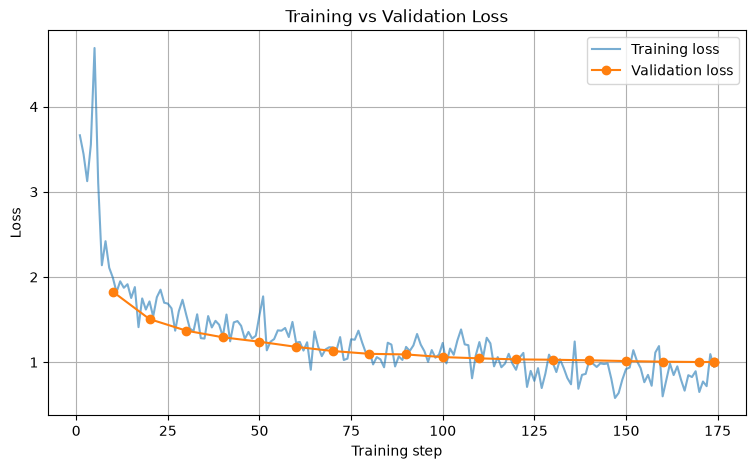

In [22]:
import math
import pandas as pd
import matplotlib.pyplot as plt

final_eval = trainer.evaluate()
print(f"Held-out loss      : {final_eval['eval_loss']:.4f}")
print(f"Held-out perplexity: {math.exp(final_eval['eval_loss']):.2f}")

history = pd.DataFrame(trainer.state.log_history)
train_curve = history.dropna(subset=["loss"])[["step", "loss"]]
val_curve = history.dropna(subset=["eval_loss"])[["step", "eval_loss"]]

print(f"Average training loss : {trainer_stats.metrics['train_loss']:.4f}")
print(f"Last logged train loss: {train_curve['loss'].iloc[-1]:.4f}")
if len(val_curve):
    best = val_curve.loc[val_curve["eval_loss"].idxmin()]
    print(f"Best validation loss: {best['eval_loss']:.4f} (step {int(best['step'])})")
    print(f"Last validation loss: {val_curve['eval_loss'].iloc[-1]:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(train_curve["step"], train_curve["loss"], label="Training loss", alpha=0.6)
if len(val_curve):
    plt.plot(val_curve["step"], val_curve["eval_loss"], label="Validation loss", marker="o")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

### Comparing with the previous dataset (objective 4)

The earlier run used `data_kh.csv` (Khmer robot-navigation commands). This run fine-tunes on `dataasilida_cleaned.csv` (Khmer e-commerce Q&A). To compare the two experiments, report:

- the average and last logged training loss, the best/last validation loss and the held-out perplexity (printed above);
- how quickly each validation curve flattens or starts rising;
- the generated answer for the held-out test question below versus its reference answer.

Lower held-out loss and coherent in-domain answers indicate better adaptation. A rising validation loss indicates the smaller dataset starts overfitting sooner.

<a name="Inference"></a>
### Inference
Let's run the model via Unsloth native inference! According to the `Gemma-3` team, the recommended settings for inference are `temperature = 1.0, top_p = 0.95, top_k = 64`

In [23]:
from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(
    tokenizer,
    chat_template = "gemma-3",
)

# Use a held-out example so the answer shows generalization, not memorization.
test_question = dataset['test'][0]['input']
reference_answer = dataset['test'][0]['output']
print("QUESTION:", test_question)
print("\nREFERENCE ANSWER:", reference_answer)

messages = [{
    "role": "user",
    "content": [{
        "type" : "text",
        "text" : test_question,
    }]
}]
text = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt = True, # Must add for generation
)
inputs = tokenizer([text], return_tensors = "pt").to("cuda")
outputs = model.generate(
    **inputs,
    max_new_tokens = 256, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
)
print("\nGENERATED ANSWER:")
print(tokenizer.decode(outputs[0][inputs["input_ids"].shape[1]:], skip_special_tokens = True))

QUESTION: តើសេវាសុវត្ថិភាព 3D អ៉ីអន ជាអ្វី

REFERENCE ANSWER: សេវា​សុវត្ថិភាព 3D អ៉ីអន​ ជា​មុខងារ​សុវត្ថិភាព​មួយ ដែល​ផ្តល់ជូន​ដោយ ធនាគារ​​ឯកទេស អ៉ីអន (ខេមបូឌា) ភីអិលស៊ី។ មុខងារ​សេវាកម្ម​នេះ​គឺ​ត្រូវបាន​ប្រើប្រាស់ នៅ​ពេល​ដែល​លោកអ្នក​ធ្វើ​ប្រតិបត្តិការ​អនឡាញ​ជាមួយ​នឹង​អ៉ីអនកាត​នៅ​លើ​គេហទំព័រ​ពាណិជ្ជករ​អនឡាញ ដែល​បាន​ចូលរួម​ប្រើប្រាស់​សេវា​សុវត្ថិភាព​របស់​ក្រុមហ៊ុន វីសា។ លោកអ្នក​នឹង​ទទួល​បាន​លេខ​សម្ងាត់​ម្តង ដែល​មាន​៦ខ្ទង់​​តាមរយៈ​ការផ្ញើសារ​ទៅកាន់​លេខ​ទូរស័ព្ទដៃ និង អ៉ីម៉ែល របស់​លោកអ្នក​ដែល​បាន​ចុះ​ឈ្មោះ បន្ទាប់មក​គ្រាន់តែ​បញ្ចូល​លេខ​សម្ងាត់​ម្តង​ដែល​មាន​៦ខ្ទង់​នោះ ដើម្បី​ផ្ទៀងផ្ទាត់​ប្រតិបត្តិការ​របស់​លោកអ្នក។



GENERATED ANSWER:
សេវា 3D Secure អ៉ីអន (3DS) គឺជាការប្រើប្រាស់សេវាសុវត្ថិភាពលើកម្មវិធីធនាគារអ៉ីអន ដើម្បីការពារការធ្វើប្រតិបត្តិការតាមអនឡាញដោយខ្លួនឯង របស់អតិថិជនដោយមិនបណ្តាលមកដល់ការទូទាត់ក្នុងប្រតិបត្តិការសុទ្ធរាល់កម្រិត ដែលទាក់ទងនឹងប្រតិបត្តិការតាមអនឡាញ ដោយផ្អែកតាមឧបករណ៍សម្គាល់អត្តសញ្ញាណដែលមានស្រាក្នុងខ្លួន។


 You can also use a `TextStreamer` for continuous inference - so you can see the generation token by token, instead of waiting the whole time!

In [24]:
messages = [{
    "role": "user",
    "content": [{"type" : "text", "text" : dataset['test'][0]['input'],}]
}]
text = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt = True, # Must add for generation
)

from transformers import TextStreamer
_ = model.generate(
    **tokenizer([text], return_tensors = "pt").to("cuda"),
    max_new_tokens = 256, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
    streamer = TextStreamer(tokenizer, skip_prompt = True),
)

សេវាសុវត្ថិភាព 

3D 

ម៉ាសើរ 

គឺជា 

ភាពអាចជឿទុកចិត្ត 

បង្ការការគំរាមុ 

... (4 outputs left out)

ភីអិលស៊ី 

ដោយមានការប្រើប្រាស់កម្មវិធីវ៉េបសេវាកម្ម 

ផ្ទេរប្រាក់ជាទិញ 

ដោយចាត់ចែងដោយស្វ័យប្រវត្តិ។<end_of_turn>


<a name="Save"></a>
### Saving, loading finetuned models
To save the final model as LoRA adapters, either use Huggingface's `push_to_hub` for an online save or `save_pretrained` for a local save.

**[NOTE]** This ONLY saves the LoRA adapters, and not the full model. To save to 16bit or GGUF, scroll down!

In [25]:
model.save_pretrained("gemma-3")  # Local saving
tokenizer.save_pretrained("gemma-3")
# model.push_to_hub("HF_ACCOUNT/gemma-3", token = "...") # Online saving
# tokenizer.push_to_hub("HF_ACCOUNT/gemma-3", token = "...") # Online saving

/root/tp04-env/lib/python3.12/site-packages/peft/utils/save_and_load.py:313: UserWarning: Could not find a config file in unsloth/gemma-3-4b-it-unsloth-bnb-4bit - will assume that the vocabulary was not modified.
  warnings.warn(


Unsloth: Restored added_tokens_decoder metadata in gemma-3/tokenizer_config.json.


Unsloth: Preserved sentencepiece asset `tokenizer.model` in gemma-3.


['gemma-3/processor_config.json']

Now if you want to load the LoRA adapters we just saved for inference, set `False` to `True`:

In [26]:
if False:
    from unsloth import FastModel
    model, tokenizer = FastModel.from_pretrained(
        model_name = "lora_model", # YOUR MODEL YOU USED FOR TRAINING
        max_seq_length = 2048,
        load_in_4bit = True,
    )

messages = [{
    "role": "user",
    "content": [{"type" : "text", "text" : "បន្តទៅក្រោយ៩ម",}]
}]
text = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt = True, # Must add for generation
)

from transformers import TextStreamer
_ = model.generate(
    **tokenizer([text], return_tensors = "pt").to("cuda"),
    max_new_tokens = 64, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
    streamer = TextStreamer(tokenizer, skip_prompt = True),
)

សូមពិរោះ។<end_of_turn>


### Saving to float16 for VLLM

We also support saving to `float16` directly for deployment! We save it in the folder `gemma-3-finetune`. Set `if False` to `if True` to let it run!

In [27]:
if False: # Change to True to save finetune!
    model.save_pretrained_merged("gemma-3-finetune", tokenizer)

If you want to upload / push to your Hugging Face account, set `if False` to `if True` and add your Hugging Face token and upload location!

In [28]:
if False: # Change to True to upload finetune
    model.push_to_hub_merged(
        "HF_ACCOUNT/gemma-3-finetune", tokenizer,
        token = "hf_..."
    )

In [29]:
if False: # Change to True to save to GGUF
    model.save_pretrained_gguf(
        "gemma-3-finetune",
        quantization_type = "Q8_0", # For now only Q8_0, BF16, F16 supported
    )

Likewise, if you want to instead push to GGUF to your Hugging Face account, set `if False` to `if True` and add your Hugging Face token and upload location!

In [30]:
if False: # Change to True to upload GGUF
    model.push_to_hub_gguf(
        "gemma-3-finetune",
        quantization_type = "Q8_0", # Only Q8_0, BF16, F16 supported
        repo_id = "HF_ACCOUNT/gemma-finetune-gguf",
        token = "hf_...",
    )